In [ ]:
%matplotlib inline

# Notebook 2 — Build a DBA ring

**Build an electron storage ring from identical double-bend achromat (DBA) cells**.

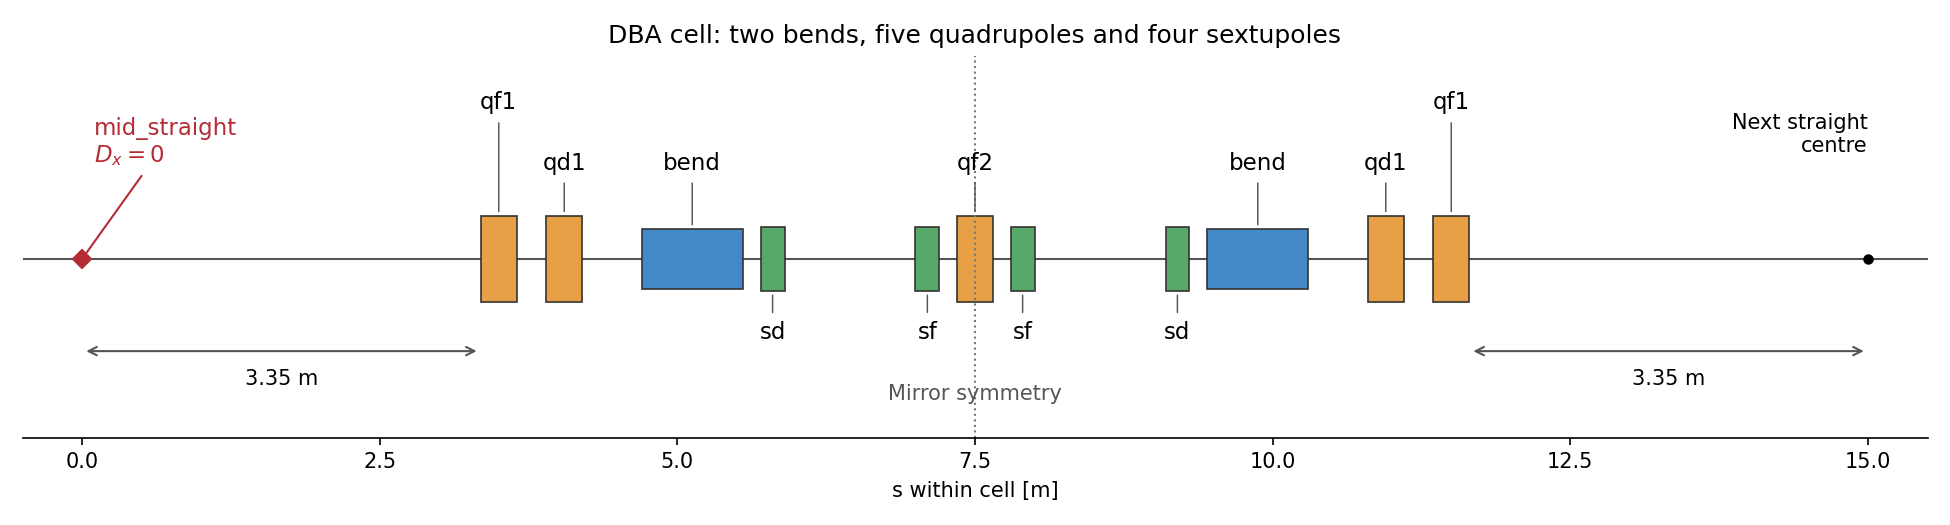

Indicative cell layout. Quadrupoles with the same name have the same strength.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical DBA cells | 16 |
| Phase advance per cell (horizontal / vertical) | 333° / 150.75° |
| Dipole type | Sector bend (`xt.Bend`) |
| Dipole length | 0.85 m |
| Quadrupole length | 0.30 m |
| Sextupole length | 0.20 m |
| Ring chromaticity | 0.5 / 0.5 |

Use the following **magnet-centre positions in the first half-cell**, including the cell centre:

| Family | Centre position [m] |
|---|---|
| qf1 | 3.50 |
| qd1 | 4.05 |
| Bend | 5.125 |
| qf2 | 7.50 |
| sf | 7.10 |
| sd | 5.80 |

### Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Create xsuite environment

In [ ]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

### Geometry parameters

In [ ]:
# env['angle_bend'] = ...

# env['l_cell'] = ...
# env['l_bend'] = ...
# ...

### Magnet strengths (initialized to zero)

In [ ]:
# env['kqf1'] = 0.0
# env['kqf2'] = ...
# env['kqd1'] = ...

# env['ksf'] = ...
# ...

### Define the magnets and build the cell

In [ ]:
# Define elements
# env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)

# env.new('qf1', xt.Quadrupole, ...)
# env.new('qf2', xt.Quadrupole, ...)
# env.new('qd1', xt.Quadrupole, ...)

# env.new('sf', xt.Sextupole, length='l_sext', k2=...)
# env.new('sd', xt.Sextupole, ...)

# env.new('mid_straight', xt.Marker)

### Define cell

Use `anchor='center'` and mirror each first-half position with an expression such as `at='l_cell - 3.50'`, as shown for `qf1` below. Place the central `qf2` only once.

In [ ]:
# cell = env.new_line(length=env['l_cell'], components=[
#     env.place('mid_straight', at=0),

#     # Quadrupoles
#     env.place('qf1', anchor='center', at=3.50),
#     env.place('qf1', anchor='center', at='l_cell - 3.50'),
#     ...

#     # Bends
#     ...

#     # Sextupoles
#     ...
# ])

### Survey the cell

In [ ]:
sv_cell = cell.survey()
sv_cell.plot()

### Set starting quadrupole strengths and compute initial twiss

In [ ]:
env['kqf1'] = 3
env['kqd1'] = -3
env['kqf2'] = 3

In [ ]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell phase advances and dispersion

Impose $D_x=0$ at `mid_straight` to make the cell an achromat. Vary all three quadrupole strengths.

In [ ]:
# Optimize cell periodic solution to obtain desired phase advances and dispersion
# opt_cell = cell.match(
#     solve=False,
#     method='4d',
#     vary=[
#         xt.Vary('kqf1', limits=(0, 100), step=1e-5),
#         xt.Vary('kqf2', ...),
#         xt.Vary('kqd1', ...),
#     ],
#     targets=[
#         xt.TargetSet(qx=333/360., qy=..., tol=1e-8),
#         xt.TargetSet(dx=..., at='mid_straight', tol=1e-8),
#     ],
# )

In [ ]:
# Before optimization
opt_cell.target_status()

In [ ]:
# Optimize
opt_cell.run_jacobian(30)

In [ ]:
# After optimization
opt_cell.target_status()
opt_cell.vary_status()

### Inspect the matched cell optics

In [ ]:
tw_cell = cell.twiss4d()
tw_cell.plot()

In [ ]:
# Inspect the dispersion at the straight centre
tw_cell.rows['mid_straight'].cols['dx dpx']

### Assemble the ring

In [ ]:
# n_cells = ...
# ring = n_cells * cell

### Give unique names to all elements

In [ ]:
ring.replace_all_repeated_elements()

### Survey

In [ ]:
sv = ring.survey()

In [ ]:
sv.plot()

### Full-ring optics

In [ ]:
tw_ring = ring.twiss4d()
tw_ring.plot()

In [ ]:
# Inspect tunes
tw_ring.qx, tw_ring.qy

### Correct the chromaticities

In [ ]:
# opt_chrom = ring.match(
#     solve=False,
#     method='4d',
#     vary=[
#         xt.Vary('ksf', limits=(0, 100), step=1e-3),
#         xt.Vary('ksd', ...),
#     ],
#     targets=xt.TargetSet(dqx=0.5, ... , tol=0.001),
# )

In [ ]:
opt_chrom.run_jacobian(30)

In [ ]:
opt_chrom.target_status()
opt_chrom.vary_status()

### Final tunes and chromaticities

In [ ]:
tw_ring = ring.twiss4d()
print(f'Tunes: {tw_ring.qx:.6f} / {tw_ring.qy:.6f}')
print(f'Chromaticities: {tw_ring.dqx:.6f} / {tw_ring.dqy:.6f}')

### Save the ring

In [ ]:
ring.to_json('ring_dba.json')